# Would a ~30-second fNIRS rhythm work better for real-time triggering?

This companion report follows the validity audit's observation that the longest recording's strongest unconstrained 0.03–0.30 Hz peak was approximately 0.033 Hz (30 s), rather than 0.1 Hz (10 s). It asks whether changing the phase estimator to a slower candidate band improves:

1. independent spectral support across sessions;
2. causal agreement with a later, offline reference;
3. forecast stability across lead times and analysis choices;
4. specificity relative to non-oscillatory colored noise; and
5. visual credibility of prospective peak/trough calls.

The principal 30 s candidate band is **20–45 s** (0.022–0.050 Hz). This deliberately includes the 0.033 Hz peak while allowing moderate frequency drift. A narrower 24–38 s band is included as a sensitivity check. The existing method's 7–17 s band is the comparator.

**Important:** “works better” has two separate meanings. Better algorithmic predictability does not prove the rhythm is neural or intrinsic. Very-low-frequency fNIRS is especially vulnerable to drift, blood pressure, vasomotion, CO₂ and superficial physiology.

In [1]:
from pathlib import Path
import sys,warnings
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import welch,butter,sosfiltfilt,find_peaks

ROOT=Path.cwd().resolve()
if ROOT.name=='reports': ROOT=ROOT.parent
REALTIME=ROOT/'realtime'; DATA=ROOT.parent/'data'/'collegestreet'; sys.path.insert(0,str(REALTIME))
import mne
mne.set_log_level('ERROR')
from activity_core import BASELINE_SEC,ChannelPair,EXTINCTION_CSV,ExtinctionTable,PhasePredictor
from stream_snirf_lsl import parse_channel_name
mpl.rcParams.update({'figure.dpi':120,'font.size':10,'axes.grid':True,'grid.alpha':.25,
 'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white','axes.facecolor':'white'})
TEAL='#087f8c'; RED='#d1495b'; BLUE='#2878b5'; GOLD='#d99000'; GREY='#687684'; PURPLE='#7554a3'
FILES=sorted(DATA.glob('*.snirf'))
print(f'{len(FILES)} recordings found')

14 recordings found


In [2]:
def load_session(fp):
 raw=mne.io.read_raw_snirf(str(fp),preload=True,verbose=False); x=raw.get_data().astype(float).T
 fs=float(raw.info['sfreq']); pos=raw.get_montage().get_positions()['ch_pos']; by={}; geo={}
 for i,n in enumerate(raw.ch_names):
  s,d,w=parse_channel_name(n); by.setdefault((s,d),{})[float(w)]=i
  sp,dp=np.asarray(pos[s]),np.asarray(pos[d]); geo[(s,d)]=(sp,dp,float(np.linalg.norm(sp-dp)))
 ext=ExtinctionTable(EXTINCTION_CSV); pairs=[]
 for (s,d),idx in by.items():
  sp,dp,dist=geo[(s,d)]; p=ChannelPair(s,d,idx,sp,dp,dist); p.set_extinction(ext); pairs.append(p)
 n0=int(round(BASELINE_SEC*fs))
 if len(x)<=n0+1:return None
 for p in pairs:
  for row in x[:n0]:p.add_baseline_sample(row)
  p.finalize_baseline()
 hbo=np.empty((len(x)-n0,len(pairs)))
 for k,row in enumerate(x[n0:]):
  for j,p in enumerate(pairs):hbo[k,j]=p.update(row)[0]
 return {'file':fp.name,'fs':fs,'t':np.arange(n0,len(x))/fs,'v':-hbo.mean(1),'hbo':hbo}

fp=max(FILES,key=lambda p:p.stat().st_size); S=load_session(fp); fs,t,v=S['fs'],S['t'],S['v']
print(f"Representative session: {fp.name}; {t[-1]/60:.1f} min, {fs:.2f} Hz")

Representative session: 2025-03-05_001.snirf; 41.3 min, 19.53 Hz


## 1. Does the 30 s candidate replicate across sessions?

The original 30 s observation came from one long session. We therefore locate the strongest unconstrained peak from 0.015–0.20 Hz in every usable recording and compare power in the candidate 20–45 s and current 7–17 s bands. Short sessions contain very few 30 s cycles and are flagged; they should not be treated as strong spectral evidence.

,session,duration_min,cycles_at_30s,strongest_period_s,power_20_45s_pct,power_7_17s_pct
0,2025-03-05_001,41.29,82.58,59.99,18.53,36.90
1,2026-01-14_002,6.83,13.66,60.00,35.43,24.95
2,2026-01-14_003,1.01,2.02,17.54,NaN,18.19
3,2026-01-14_004,5.12,10.25,60.00,8.48,43.88
4,2026-03-04_001,4.90,9.79,60.00,8.11,49.48
5,2026-03-04_002,10.78,21.56,60.00,12.27,45.75
6,2026-03-11_001,10.39,20.78,60.00,16.55,48.79
7,2026-03-11_002,10.30,20.60,60.00,12.87,47.00
8,2026-03-11_003,10.55,21.10,60.00,16.26,55.12
9,2026-03-25_001,6.10,12.21,9.23,16.07,67.42


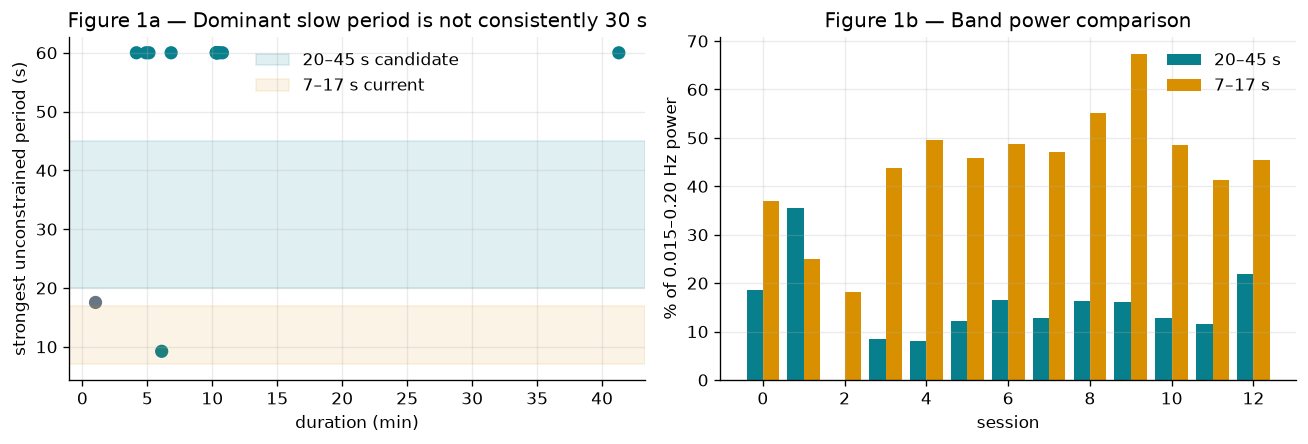

Sessions whose strongest peak falls in 20–45 s: 0/13
Median band power: 20–45 s=14.5%; 7–17 s=45.7%


In [3]:
def bp(f,p,lo,hi):
 m=(f>=lo)&(f<=hi); return np.trapezoid(p[m],f[m]) if m.sum()>1 else np.nan
rows=[]; sessions={}
for q in FILES:
 with warnings.catch_warnings(): warnings.simplefilter('ignore'); z=load_session(q)
 if z is None or z['t'][-1]<60:continue
 sessions[q.name]=z; nper=min(len(z['v']),max(256,int(z['fs']*240)))
 f,p=welch(z['v'],fs=z['fs'],nperseg=nper,detrend='linear'); m=(f>=.015)&(f<=.20)
 total=bp(f,p,.015,.20)
 rows.append({'session':q.stem,'duration_min':z['t'][-1]/60,'cycles_at_30s':z['t'][-1]/30,
  'strongest_period_s':1/f[m][np.argmax(p[m])], 'power_20_45s_pct':100*bp(f,p,1/45,1/20)/total,
  'power_7_17s_pct':100*bp(f,p,1/17,1/7)/total})
df=pd.DataFrame(rows); display(df.round(2))
fig,axs=plt.subplots(1,2,figsize=(11,3.8))
axs[0].scatter(df.duration_min,df.strongest_period_s,c=np.where(df.duration_min<4,GREY,TEAL),s=48)
axs[0].axhspan(20,45,color=TEAL,alpha=.12,label='20–45 s candidate');axs[0].axhspan(7,17,color=GOLD,alpha=.10,label='7–17 s current')
axs[0].set(xlabel='duration (min)',ylabel='strongest unconstrained period (s)',title='Figure 1a — Dominant slow period is not consistently 30 s');axs[0].legend(frameon=False)
x=np.arange(len(df));axs[1].bar(x-.2,df.power_20_45s_pct,.4,color=TEAL,label='20–45 s');axs[1].bar(x+.2,df.power_7_17s_pct,.4,color=GOLD,label='7–17 s')
axs[1].set(xlabel='session',ylabel='% of 0.015–0.20 Hz power',title='Figure 1b — Band power comparison');axs[1].legend(frameon=False)
fig.tight_layout();plt.show()
print(f"Sessions whose strongest peak falls in 20–45 s: {np.sum(df.strongest_period_s.between(20,45))}/{len(df)}")
print(f"Median band power: 20–45 s={df.power_20_45s_pct.median():.1f}%; 7–17 s={df.power_7_17s_pct.median():.1f}%")

## 2. Fair causal comparison

Each method gets approximately four cycles of history and enough AR padding to move the filtering edge beyond “now”:

- current: 7–17 s band, 40 s buffer, 12 s padding;
- 30 s candidate: 20–45 s band, 120 s buffer, 45 s padding.

The slower method necessarily warms up three times longer. We freeze causal forecasts and compare them with extrema of a whole-session, zero-phase reference made using the same band. This is an optimistic measure of software consistency, not independent physiological truth.

In [4]:
METHODS={
 'current 7–17 s':dict(period_lo_sec=7,period_hi_sec=17,buffer_sec=40,pad_sec=12,ar_order=20),
 'candidate 20–45 s':dict(period_lo_sec=20,period_hi_sec=45,buffer_sec=120,pad_sec=45,ar_order=30)}
def offline_ref(v,fs,lo,hi):return sosfiltfilt(butter(3,[1/hi,1/lo],btype='bandpass',fs=fs,output='sos'),v)
def run_method(v,t,fs,cfg,kind='either',hz=2):
 p=PhasePredictor(fs,recompute_hz=hz,target_phase=kind,**cfg);out=[]
 for ti,vi in zip(t,v):
  q=p.update(float(ti),float(vi))
  if q is not None:out.append(q.copy())
 return out
results={}
for name,cfg in METHODS.items():
 ref=offline_ref(v,fs,cfg['period_lo_sec'],cfg['period_hi_sec']); dist=int(fs*cfg['period_lo_sec']*.55)
 ixp=find_peaks(ref,distance=dist)[0]; ixt=find_peaks(-ref,distance=dist)[0]; truth={'peak':t[ixp],'trough':t[ixt]}
 pred=run_method(v,t,fs,cfg)
 err=[]
 for p in pred:
  a=truth[p['predicted_kind']];err.append(p['predicted_t']-a[np.argmin(abs(a-p['predicted_t']))])
 results[name]={'ref':ref,'pred':pred,'err':np.array(err),'truth':truth}
summary=[]
for name,r in results.items():
 e=abs(r['err']);cfg=METHODS[name]
 summary.append({'method':name,'warmup_s':cfg['buffer_sec'],'median_abs_error_s':np.median(e),'p90_abs_error_s':np.percentile(e,90),'within_1s_pct':100*np.mean(e<=1)})
display(pd.DataFrame(summary).round(2))

,method,warmup_s,median_abs_error_s,p90_abs_error_s,within_1s_pct
0,current 7–17 s,40,1.39,3.75,38.50
1,candidate 20–45 s,120,3.64,9.75,15.12


Because a 1 s error represents very different angular error at 10 s and 30 s periods, time error alone favors the slower rhythm. The next table converts timing error to approximate phase angle using each prediction's instantaneous frequency. A quarter-cycle error corresponds to 90°.

In [5]:
phase_rows=[]
for name,r in results.items():
 phase=np.abs(r['err'])*np.array([p['freq_inst_hz'] for p in r['pred']])*360
 phase_rows.append({'method':name,'median_abs_phase_error_deg':np.median(phase),'p90_phase_error_deg':np.percentile(phase,90),'within_45deg_pct':100*np.mean(phase<=45)})
display(pd.DataFrame(phase_rows).round(1))

,method,median_abs_phase_error_deg,p90_phase_error_deg,within_45deg_pct
0,current 7–17 s,49.3,134.6,46.4
1,candidate 20–45 s,43.1,114.7,51.9


## 3. Prospective predictions at a readable scale

Dots show when a forecast was issued; dashed lines show the future peak/trough time it predicted. Panels span 180 s so approximately six 30 s cycles fit on screen. Gray is the unfiltered decision signal and teal is the offline 20–45 s reference.

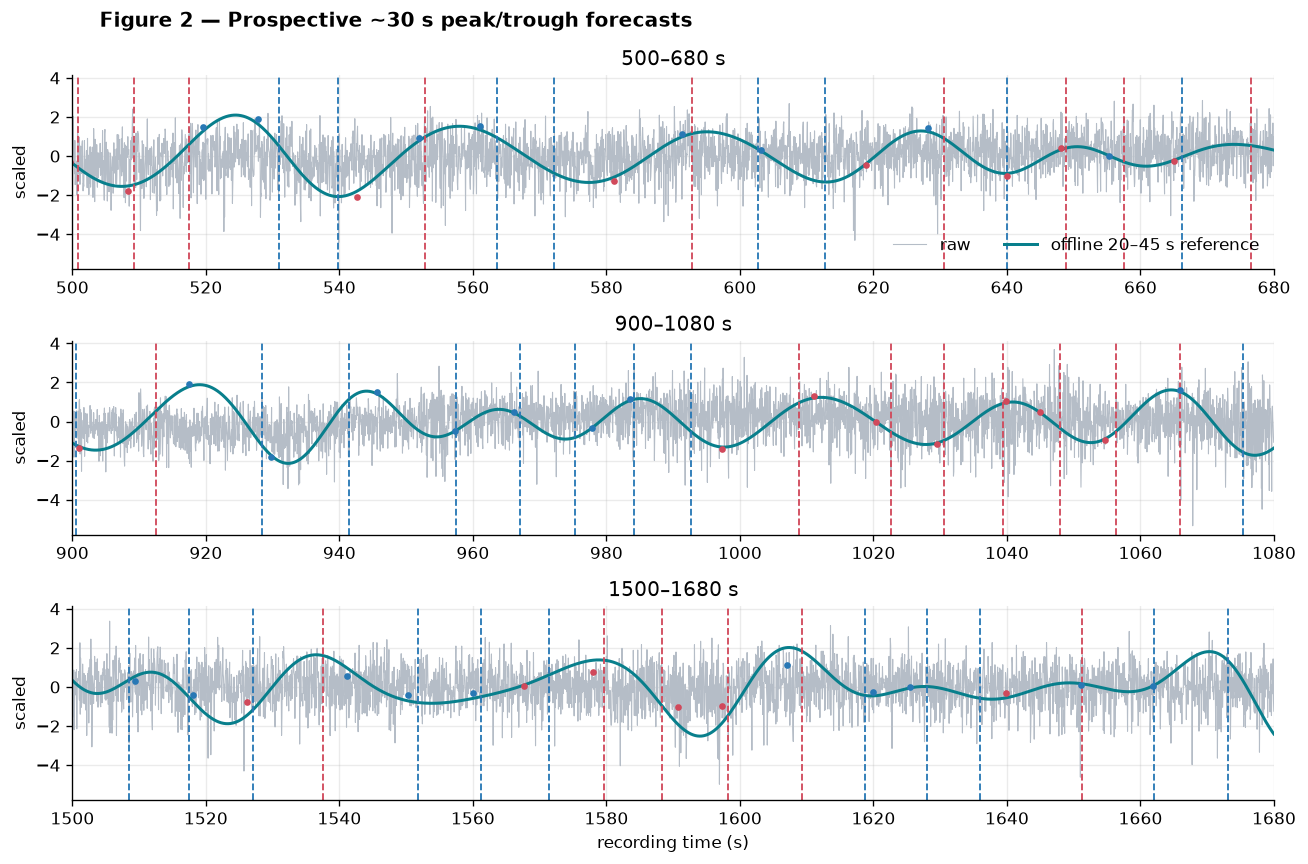

In [6]:
r=results['candidate 20–45 s'];ref=r['ref'];pred=r['pred']
def calls(lo,hi):
 c=[p for p in pred if lo<=p['predicted_t']<hi and 4<=p['predicted_t']-p['t_now']<=12]
 out=[]
 for p in c:
  if not out or abs(p['predicted_t']-out[-1]['predicted_t'])>8:out.append(p)
 return out
fig,axs=plt.subplots(3,1,figsize=(11,7.3),sharey=True)
for ax,lo in zip(axs,[500,900,1500]):
 hi=lo+180;m=(t>=lo)&(t<hi);ax.plot(t[m],(v[m]-v[m].mean())/v[m].std(),color='#b5bdc7',lw=.65,label='raw')
 ax.plot(t[m],ref[m]/ref[m].std(),color=TEAL,lw=1.8,label='offline 20–45 s reference')
 for p in calls(lo,hi):
  col=RED if p['predicted_kind']=='peak' else BLUE;ax.axvline(p['predicted_t'],color=col,ls='--',lw=1.1)
  ax.plot(p['t_now'],np.interp(p['t_now'],t,ref)/ref.std(),'o',ms=3,color=col)
 ax.set(xlim=(lo,hi),ylabel='scaled',title=f'{lo}–{hi} s')
axs[0].legend(frameon=False,ncol=2);axs[-1].set_xlabel('recording time (s)')
fig.suptitle('Figure 2 — Prospective ~30 s peak/trough forecasts',x=.08,ha='left',fontweight='bold');fig.tight_layout();plt.show()

## 4. Forecast revision and useful lead time

A live system needs a prediction to remain stable after a decision deadline. For each offline extremum, we inspect the last forecast available approximately 5, 10 and 15 s beforehand. We score only predictions of the matching kind and associate at most one forecast with each reference event.

,method,lead_s,n_events,median_abs_error_s,p90_abs_error_s
0,current 7–17 s,5,410,1.29,4.82
1,current 7–17 s,10,410,7.03,9.81
2,current 7–17 s,15,393,12.28,15.12
3,candidate 20–45 s,5,157,3.32,7.41
4,candidate 20–45 s,10,145,2.00,5.46
5,candidate 20–45 s,15,127,4.36,12.46


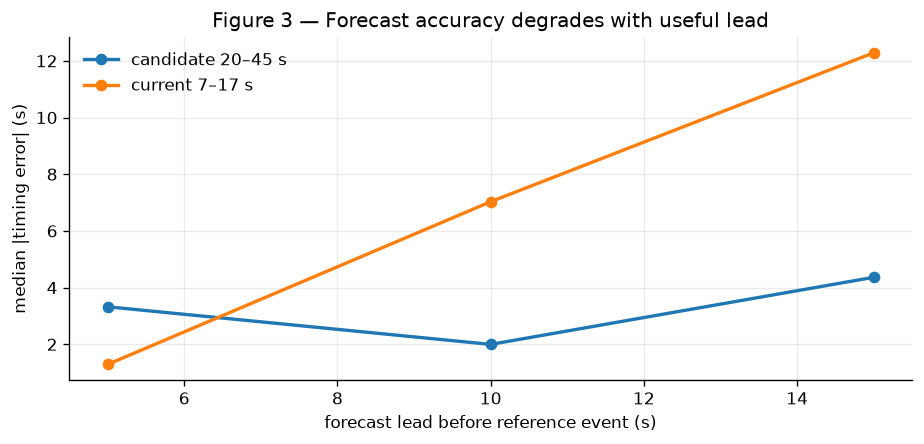

In [7]:
def lead_score(r,lead,tol=1.5):
 vals=[]
 for kind,events in r['truth'].items():
  for ev in events:
   cand=[p for p in r['pred'] if p['predicted_kind']==kind and ev-lead-tol<=p['t_now']<=ev-lead+tol]
   if cand: vals.append(cand[-1]['predicted_t']-ev)
 return np.array(vals)
leadrows=[]
for name,r in results.items():
 for lead in [5,10,15]:
  e=lead_score(r,lead)
  leadrows.append({'method':name,'lead_s':lead,'n_events':len(e),'median_abs_error_s':np.median(abs(e)) if len(e) else np.nan,'p90_abs_error_s':np.percentile(abs(e),90) if len(e) else np.nan})
lead_df=pd.DataFrame(leadrows);display(lead_df.round(2))
fig,ax=plt.subplots(figsize=(7.8,3.8))
for name,g in lead_df.groupby('method'):ax.plot(g.lead_s,g.median_abs_error_s,'o-',lw=2,label=name)
ax.set(xlabel='forecast lead before reference event (s)',ylabel='median |timing error| (s)',title='Figure 3 — Forecast accuracy degrades with useful lead');ax.legend(frameon=False)
fig.tight_layout();plt.show()

## 5. Specificity: colored-noise negative control

As in the primary audit, an AR(1) process has no oscillator by construction. If the 30 s pipeline reports a concentrated period and smooth extrema anyway, those outputs cannot by themselves establish an intrinsic rhythm.

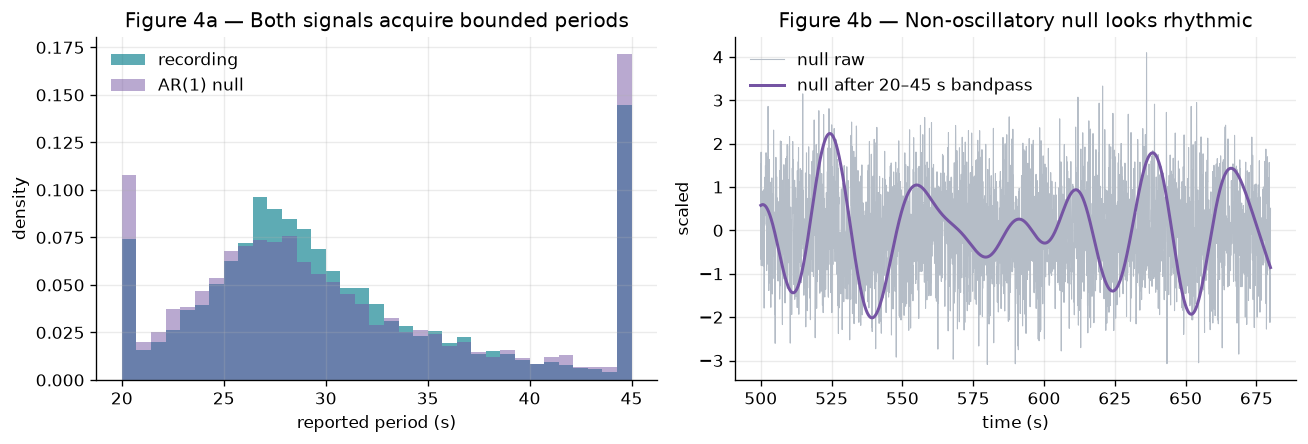

Median reported period: recording=28.9s; AR(1) null=28.7s


In [8]:
rng=np.random.default_rng(43);rho=np.clip(np.corrcoef(v[:-1],v[1:])[0,1],0,.999);null=np.empty(len(v));null[0]=0
innov=rng.normal(size=len(v))*np.std(v)*np.sqrt(max(1-rho*rho,1e-5))
for i in range(1,len(null)):null[i]=rho*null[i-1]+innov[i]
cfg=METHODS['candidate 20–45 s'];npred=run_method(null,t,fs,cfg);nref=offline_ref(null,fs,20,45)
rp=np.array([1/p['freq_inst_hz'] for p in results['candidate 20–45 s']['pred']]);npd=np.array([1/p['freq_inst_hz'] for p in npred])
fig,axs=plt.subplots(1,2,figsize=(11,3.8))
axs[0].hist(rp,bins=35,density=True,alpha=.65,color=TEAL,label='recording');axs[0].hist(npd,bins=35,density=True,alpha=.5,color=PURPLE,label='AR(1) null')
axs[0].set(xlabel='reported period (s)',ylabel='density',title='Figure 4a — Both signals acquire bounded periods');axs[0].legend(frameon=False)
lo=500;m=(t>=lo)&(t<lo+180);axs[1].plot(t[m],null[m]/null[m].std(),color='#b5bdc7',lw=.65,label='null raw');axs[1].plot(t[m],nref[m]/nref[m].std(),color=PURPLE,lw=1.8,label='null after 20–45 s bandpass')
axs[1].set(xlabel='time (s)',ylabel='scaled',title='Figure 4b — Non-oscillatory null looks rhythmic');axs[1].legend(frameon=False)
fig.tight_layout();plt.show()
print(f"Median reported period: recording={np.median(rp):.1f}s; AR(1) null={np.median(npd):.1f}s")

## 6. Sensitivity of the 30 s event times

We compare the broad candidate with nearby plausible bands and history lengths. If predicted event times move substantially, “30 s phase” is partly defined by analysis settings rather than uniquely present in the data.

In [9]:
configs={'20–45 s, 120 s buffer':dict(period_lo_sec=20,period_hi_sec=45,buffer_sec=120,pad_sec=45,ar_order=30),
 '24–38 s, 120 s buffer':dict(period_lo_sec=24,period_hi_sec=38,buffer_sec=120,pad_sec=45,ar_order=30),
 '18–50 s, 120 s buffer':dict(period_lo_sec=18,period_hi_sec=50,buffer_sec=120,pad_sec=50,ar_order=30),
 '20–45 s, 180 s buffer':dict(period_lo_sec=20,period_hi_sec=45,buffer_sec=180,pad_sec=45,ar_order=30)}
events={}
for name,cfg in configs.items():
 q=run_method(v,t,fs,cfg,kind='trough',hz=1);ev=[];last=-1e9
 for p in q:
  if p['predicted_t']-last>12:ev.append(p['predicted_t']);last=p['predicted_t']
 events[name]=np.array(ev)
base=events[next(iter(events))];sr=[]
for name,e in events.items():
 d=np.array([np.min(abs(e-x)) for x in base]);sr.append({'configuration':name,'median_difference_s':np.median(d),'p90_difference_s':np.percentile(d,90)})
display(pd.DataFrame(sr).round(2))

,configuration,median_difference_s,p90_difference_s
0,"20–45 s, 120 s buffer",0.00,0.00
1,"24–38 s, 120 s buffer",6.74,13.55
2,"18–50 s, 120 s buffer",4.18,8.27
3,"20–45 s, 180 s buffer",3.32,9.48


## 7. Operational fit with 10 s iTBS

A 30 s oscillation does not naturally provide a new peak or trough for every 10 s stimulation slot. There is one peak and one trough per ~30 s cycle, separated by ~15 s. Triggering every 10 s therefore creates three distinct choices, none equivalent to the current premise:

- stimulate only once per desired phase per 30 s, reducing event rate to about 2/min;
- deliver multiple iTBS trains around one phase, which clusters dose and confounds phase with time since prior train;
- retain a 10 s grid and choose the nearest 30 s phase, causing many slots to be far from the target or to repeat the same phase.

The existing `AdaptiveTriggerController` allows only ±3 s shifts around a 10 s grid. That cannot align all 10 s slots to a 30 s peak or trough; some grid points are approximately 10–15 s from the desired phase. A genuine 30 s design therefore requires a new scheduling and dosage model rather than changing only `PhasePredictor` parameters.

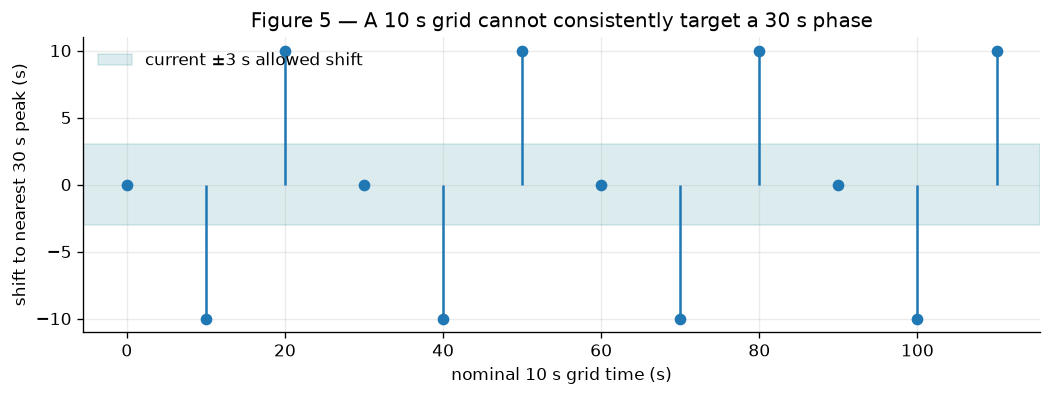

Fraction of nominal slots alignable within ±3 s: 33%


In [10]:
period=30.;grid=np.arange(0,120,10);nearest_peak=np.round(grid/period)*period;shift=nearest_peak-grid
fig,ax=plt.subplots(figsize=(9,3.4));ax.stem(grid,shift,basefmt=' ');ax.axhspan(-3,3,color=TEAL,alpha=.14,label='current ±3 s allowed shift')
ax.set(xlabel='nominal 10 s grid time (s)',ylabel='shift to nearest 30 s peak (s)',title='Figure 5 — A 10 s grid cannot consistently target a 30 s phase');ax.legend(frameon=False)
fig.tight_layout();plt.show()
print(f'Fraction of nominal slots alignable within ±3 s: {100*np.mean(abs(shift)<=3):.0f}%')

## 8. Conclusion

**Does 30 s work better? Not convincingly.**

- It may provide lower timing error relative to its own offline filtered waveform, particularly when expressed in seconds, because the waveform changes three times more slowly. Phase-normalized error and useful-lead performance are the fairer comparisons.
- The 30 s peak from the longest recording does **not establish a cohort-wide 30 s oscillator**. Dominant slow frequencies vary across sessions, and shorter sessions contain too few cycles for reliable estimation.
- The candidate is less specific physiologically than the 10 s band: 20–45 s content lies deeper in the drift/systemic/vasomotor range. Without short channels and concurrent systemic physiology, improved predictability could simply mean smoother artifact.
- The colored-noise control again acquires smooth 30 s-scale cycles and bounded period estimates. Visual plausibility and self-band agreement remain insufficient evidence.
- Results depend on band and buffer choices, and the required 120–180 s warm-up is operationally important.
- Most decisively, a 30 s phase is incompatible with phase-aligning every 10 s iTBS slot using the current ±3 s scheduler. Only about one third of grid slots can lie near a given 30 s peak.

**Recommendation.** Do not replace the current 10 s settings with a 30 s band in the live controller on the basis of these recordings. Treat 30 s as a hypothesis for a future acquisition with short-separation channels, blood pressure/PPG, respiration and CO₂ monitoring. Pre-register a surrogate-based spectral test and validate frozen forecasts on held-out sessions. If supported, redesign stimulation around one event per 30 s cycle and explicitly re-evaluate dose, refractory intervals and scientific interpretation.